# Tópicos de Minería de Datos (TMD) - λc.c

Autores: Pablo Granitto, Nicolás Soncini

Ejemplo de PCA con librería SKLearn

Explained variance ratio by each component: [0.65889506 0.25938631 0.08171863]


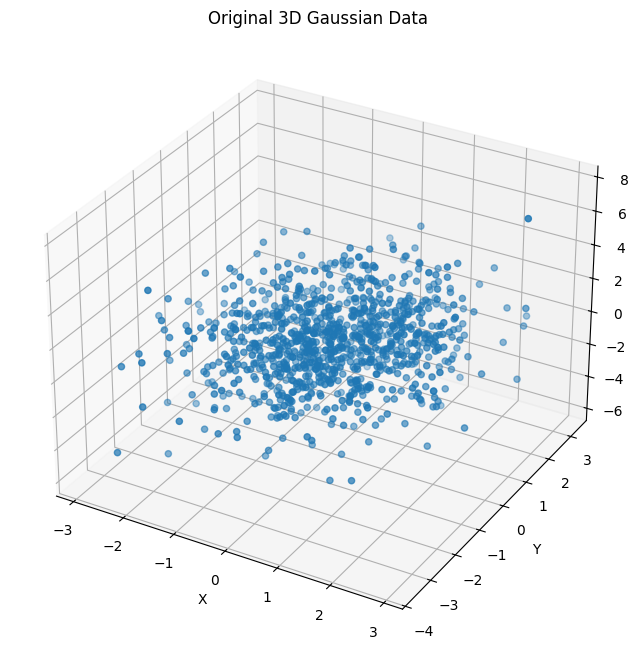

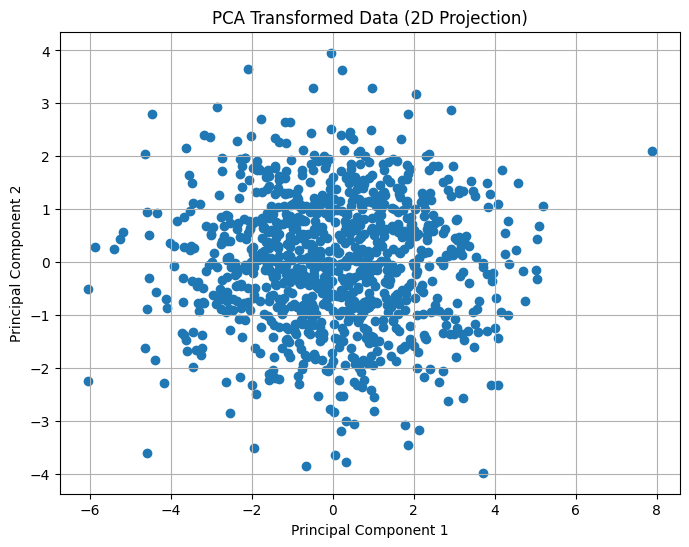

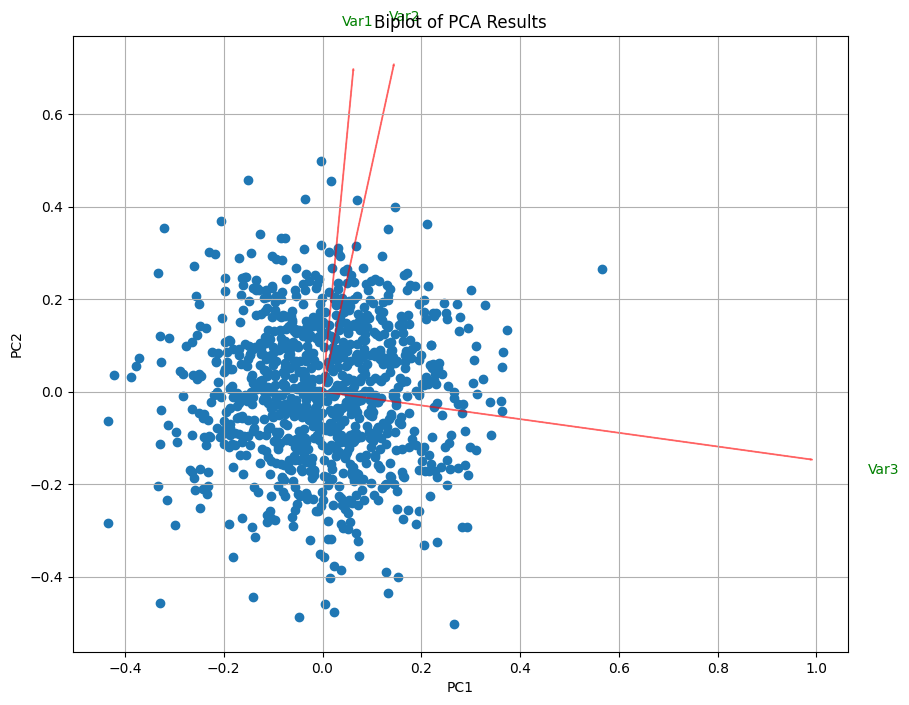

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.decomposition import PCA
import pandas as pd

# Generate 3D Gaussian data
np.random.seed(42) # for reproducibility
mean = [0, 0, 0]
cov = [[1, 0.5, 0.05],
       [0.5, 1, 0.3],
       [0.05, 0.3, 4]]

#Se puede jugar con los valores de la matriz para hacer que la distribucion se estire en una direccion o en otra. Subir las diagonales la estira en esa direccion, subir el valor que combina dos variables -siempre simetrico- lo estira en la direccion que combina esos ejes
data = np.random.multivariate_normal(mean, cov, 1000)

# Perform PCA
pca = PCA(n_components=3)
data_pca = pca.fit_transform(data)

# explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_
print(f"Explained variance ratio by each component: {explained_variance_ratio}")


# Plot original 3D data
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(data[:, 0], data[:, 1], data[:, 2])
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Original 3D Gaussian Data')
plt.show()

# Plot PCA transformed data (2D projection)
plt.figure(figsize=(8, 6))
plt.scatter(data_pca[:, 0], data_pca[:, 1])
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Transformed Data (2D Projection)')
plt.grid(True)
plt.show()

# Biplot
def biplot(score, coeff, labels=None):
    xs = score[:, 0]
    ys = score[:, 1]
    n = coeff.shape[0]
    scalex = 1.0/(xs.max() - xs.min())
    scaley = 1.0/(ys.max() - ys.min())
    plt.scatter(xs * scalex, ys * scaley)
    for i in range(n):
        plt.arrow(0, 0, coeff[i,0], coeff[i,1], color='r', alpha=0.5)
        if labels is None:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, "Var"+str(i+1), color='g', ha='center', va='center')
        else:
            plt.text(coeff[i,0]* 1.15, coeff[i,1] * 1.15, labels[i], color='g', ha='center', va='center')
    plt.xlabel("PC{}".format(1))
    plt.ylabel("PC{}".format(2))
    plt.grid()

plt.figure(figsize=(10, 8))
biplot(data_pca[:,0:2], np.transpose(pca.components_[0:2, :]), labels=['Var1', 'Var2', 'Var3'])
plt.title('Biplot of PCA Results')
plt.show()

# Instalar la libreria PCA

In [2]:
!pip install pca

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 190.4/190.4 kB 8.8 MB/s eta 0:00:00


Primer ejemplo: IRIS

[09-09-2025 13:40:40] [pca.pca] [INFO] Column labels are auto-completed.
[09-09-2025 13:40:40] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[09-09-2025 13:40:40] [pca.pca] [INFO] The PCA reduction is performed on the 4 columns of the input dataframe.
[09-09-2025 13:40:40] [pca.pca] [INFO] Fit using PCA.
[09-09-2025 13:40:40] [pca.pca] [INFO] Compute loadings and PCs.
[09-09-2025 13:40:40] [pca.pca] [INFO] Compute explained variance.
[09-09-2025 13:40:40] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[09-09-2025 13:40:40] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[09-09-2025 13:40:40] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]
[09-09-2025 13:40:40] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[09-09-2025 13:40:40] [scatterd.scatterd] [INFO] Create scatterplot


(<Figure size 700x600 with 1 Axes>,
 <Axes: title={'center': '2 Principal Components explain [95.81%] of the variance'}, xlabel='PC1 (72.9% expl.var)', ylabel='PC2 (22.8% expl.var)'>)

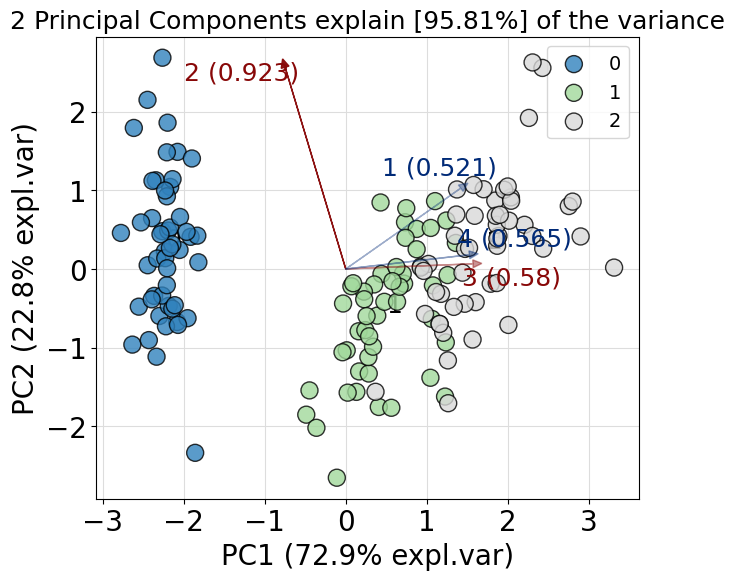

In [3]:
from pca import pca
import pandas as pd
from sklearn.datasets import load_iris

iris = load_iris()
X = iris.data
y = iris.target

# Ajustar PCA
model = pca(n_components=2,normalize=True)
results = model.fit_transform(X, y)

# Biplot automático
model.biplot(figsize=(7,6))

Segundo ejemplo: MTCARS

[09-09-2025 13:40:46] [pca.pca] [INFO] Extracting column labels from dataframe.
[09-09-2025 13:40:46] [pca.pca] [INFO] Extracting row labels from dataframe.
[09-09-2025 13:40:46] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[09-09-2025 13:40:46] [pca.pca] [INFO] The PCA reduction is performed on the 11 columns of the input dataframe.
[09-09-2025 13:40:46] [pca.pca] [INFO] Fit using PCA.
[09-09-2025 13:40:46] [pca.pca] [INFO] Compute loadings and PCs.
[09-09-2025 13:40:46] [pca.pca] [INFO] Compute explained variance.
[09-09-2025 13:40:46] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[2]
[09-09-2025 13:40:46] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[09-09-2025 13:40:46] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]
[09-09-2025 13:40:46] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[09-09-2025 13:40:47] [scatterd.scatterd] [INFO] Create s

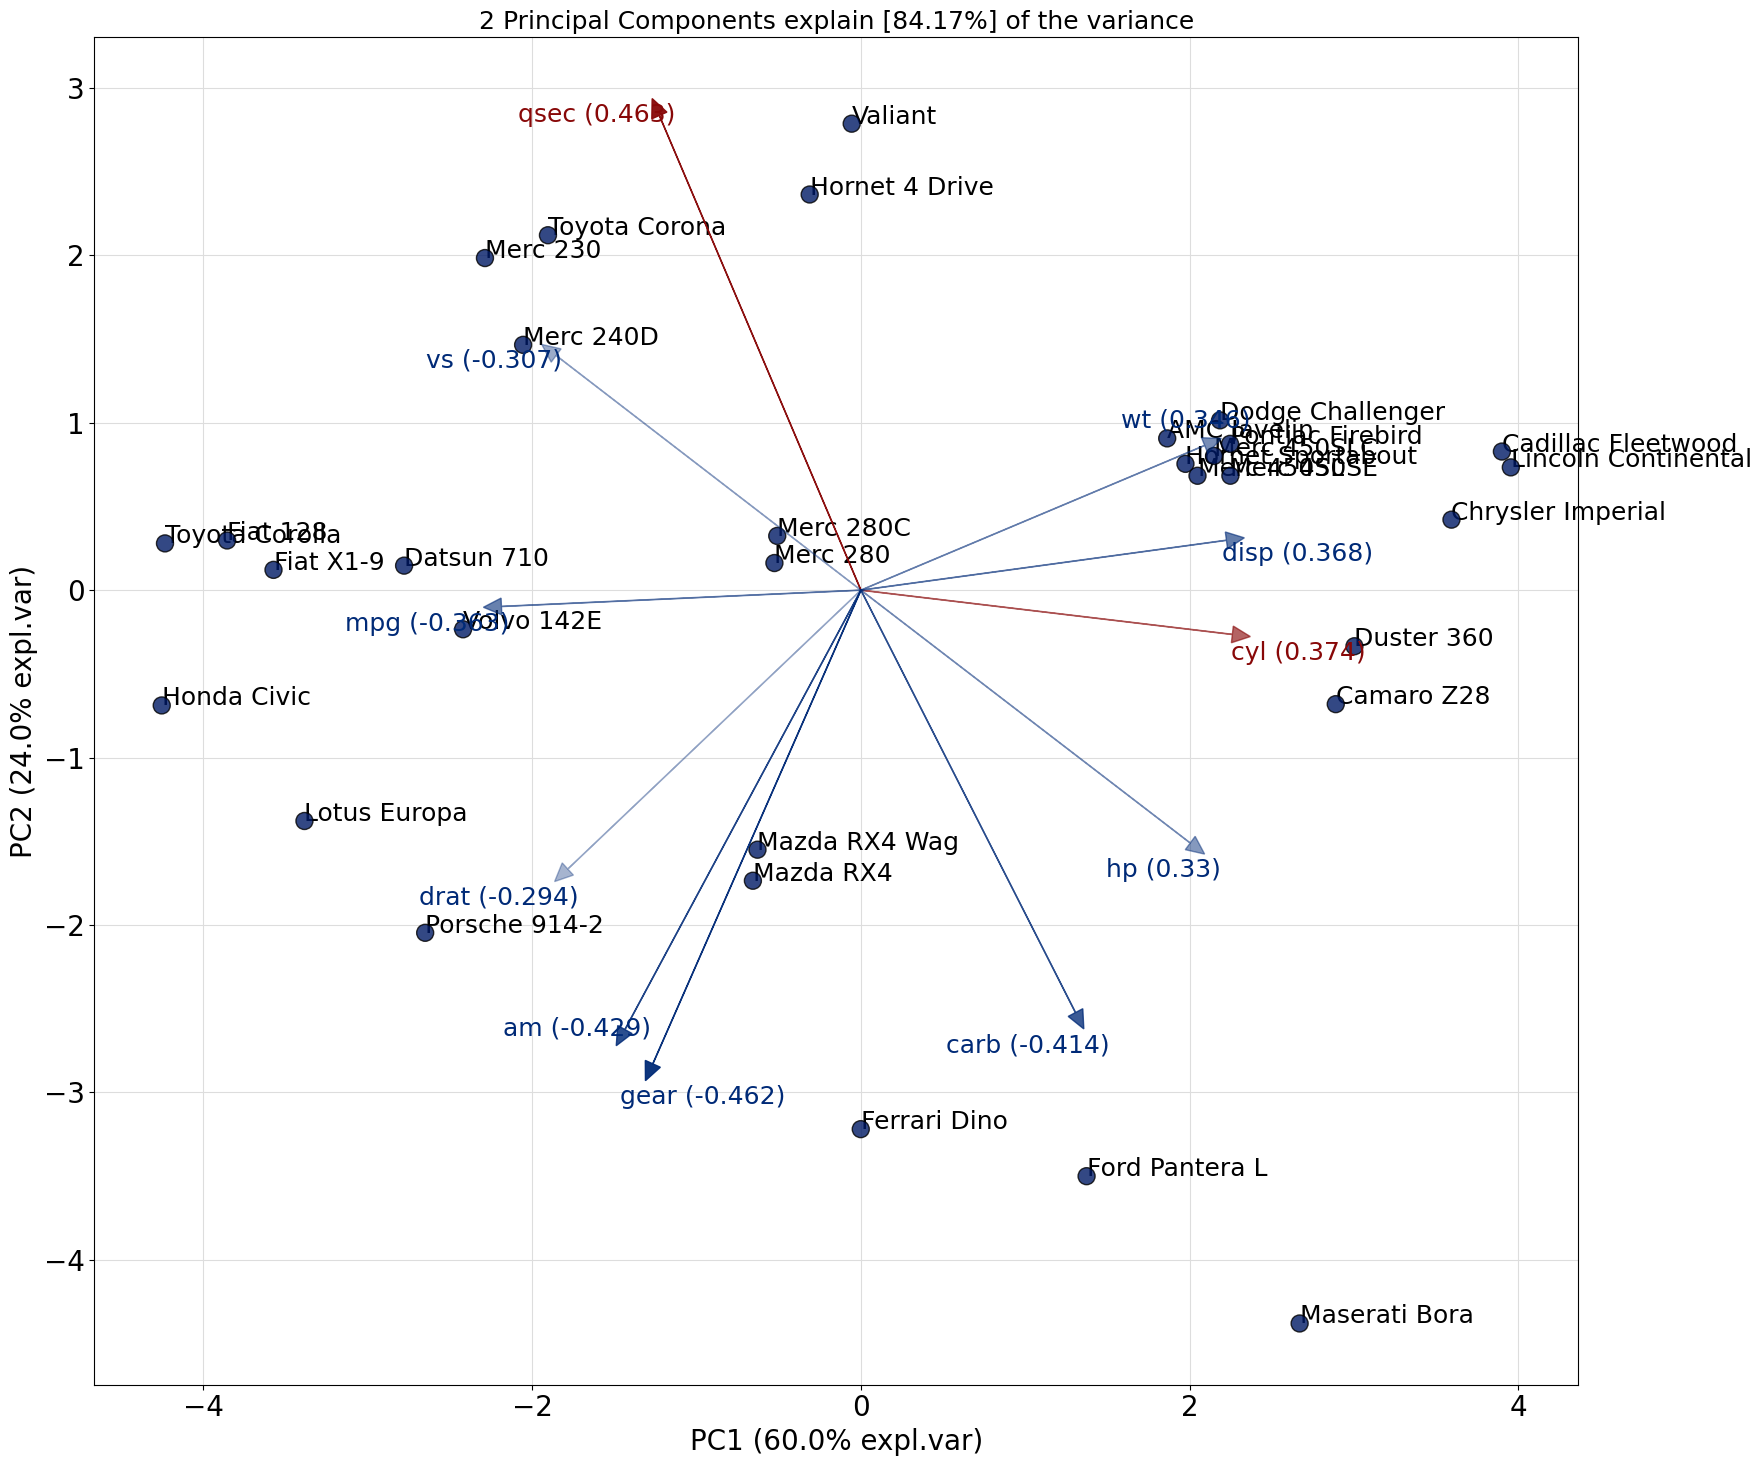

In [4]:
import statsmodels.api as sm
from pca import pca
import matplotlib.pyplot as plt

# 1) Cargar mtcars con los nombres como índice
mtcars = sm.datasets.get_rdataset("mtcars", "datasets", cache=True).data  # obtiene dataset de R
mtcars.index.name = "auto"

# 2) PCA (equivalente a scale=TRUE en R)
model = pca(n_components=2, normalize=True)
model.fit_transform(mtcars)

# 3) Biplot PC1 vs PC2 SIN mostrar aún (para poder anotar)
fig, ax = model.biplot(PC=[0, 1], n_feat=mtcars.shape[1], legend=False,figsize=(18,15))

# 4) Añadir los nombres de los autos
pc = model.results['PC'][['PC1', 'PC2']]  # coordenadas de cada auto
for name, (x, y) in pc.iterrows():
    ax.text(x, y, name, fontsize=18)

plt.tight_layout()
plt.show()




[09-09-2025 13:40:48] [pca.pca] [INFO] Extracting column labels from dataframe.
[09-09-2025 13:40:48] [pca.pca] [INFO] Extracting row labels from dataframe.
[09-09-2025 13:40:48] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[09-09-2025 13:40:48] [pca.pca] [INFO] The PCA reduction is performed on the 11 columns of the input dataframe.
[09-09-2025 13:40:48] [pca.pca] [INFO] Fit using PCA.
[09-09-2025 13:40:48] [pca.pca] [INFO] Compute loadings and PCs.
[09-09-2025 13:40:48] [pca.pca] [INFO] Compute explained variance.
[09-09-2025 13:40:48] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[8]
[09-09-2025 13:40:48] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[09-09-2025 13:40:48] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]


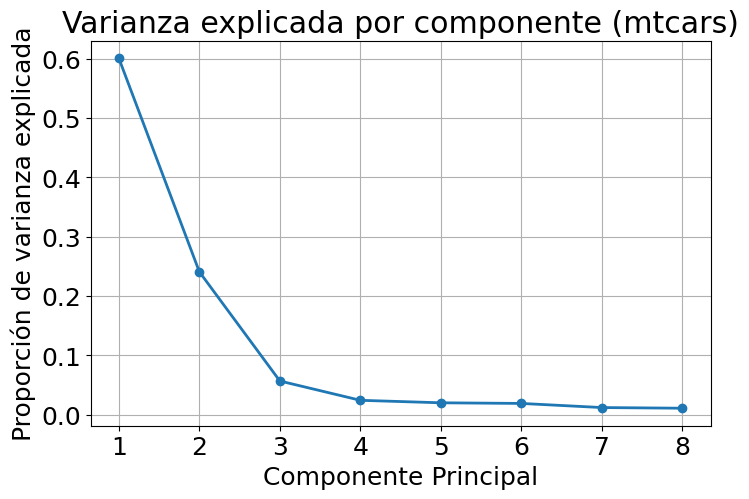

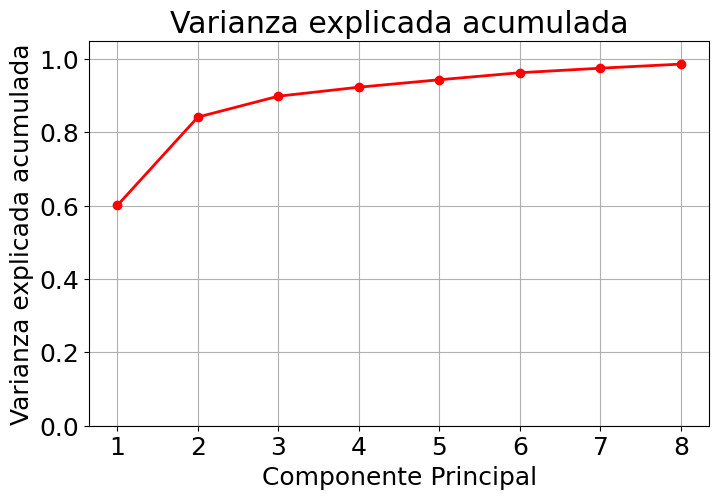

In [5]:
model = pca(n_components=8, normalize=True)
model.fit_transform(mtcars)

# Autovalores y varianza explicada
explained_var = model.results['explained_var']      # autovalores (varianzas de cada PC)
explained_var_ratio = model.results['variance_ratio']  # proporción

# Plot de varianza explicada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var_ratio) + 1), explained_var_ratio, 'o-', linewidth=2)
plt.title("Varianza explicada por componente (mtcars)")
plt.xlabel("Componente Principal")
plt.ylabel("Proporción de varianza explicada")
plt.xticks(range(1, len(explained_var_ratio) + 1))
plt.grid(True)
plt.show()

# También podés ver la acumulada
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(explained_var_ratio) + 1),
         explained_var_ratio.cumsum(), 'o-', linewidth=2, color="red")
plt.title("Varianza explicada acumulada")
plt.xlabel("Componente Principal")
plt.ylabel("Varianza explicada acumulada")
plt.xticks(range(1, len(explained_var_ratio) + 1))
plt.ylim(0, 1.05)
plt.grid(True)
plt.show()

Ejemplo de clase: dos gaussianas en d dimensiones

In [6]:
import numpy as np
import pandas as pd
from pca import pca
import matplotlib.pyplot as plt
from pandas.plotting import scatter_matrix


def crea_datos(n=100, d=2, C=0.75, n_ceros=0, random_state=None):
    rng = np.random.default_rng(random_state)

    # vector de medias (mu)
    mu = np.array([1] * (d - n_ceros) + [0] * n_ceros)

    # desviación estándar
    sigma = C * np.sqrt(np.sum(mu))

    # datos para clase 0 (centro en mu)
    x0 = rng.normal(loc=mu, scale=sigma, size=(n, d))

    # datos para clase 1 (centro en -mu)
    x1 = rng.normal(loc=-mu, scale=sigma, size=(n, d))

    # concatenar
    X = np.vstack([x0, x1])
    y = np.array([0]*n + [1]*n)

    # devolver DataFrame con clases
    cols = [f"x{i+1}" for i in range(d)]
    df = pd.DataFrame(X, columns=cols)
    df["y"] = y
    return df


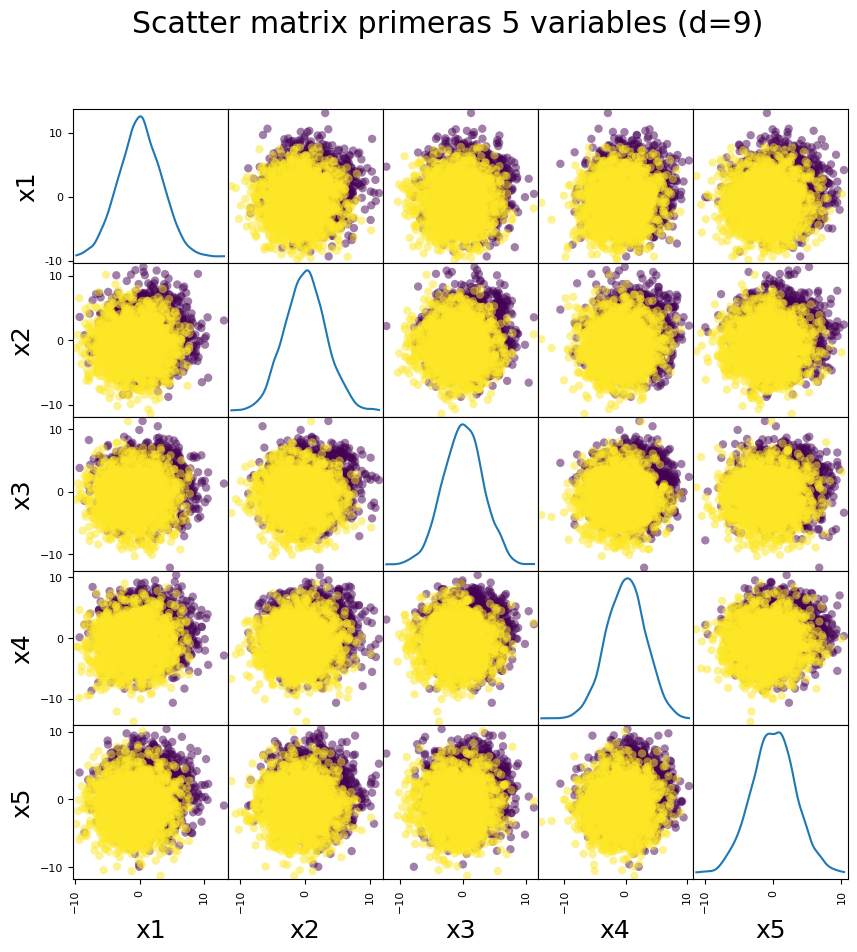

[09-09-2025 13:40:54] [pca.pca] [INFO] Extracting column labels from dataframe.
[09-09-2025 13:40:54] [pca.pca] [INFO] Extracting row labels from dataframe.
[09-09-2025 13:40:54] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[09-09-2025 13:40:54] [pca.pca] [INFO] The PCA reduction is performed on the 9 columns of the input dataframe.
[09-09-2025 13:40:54] [pca.pca] [INFO] Fit using PCA.
[09-09-2025 13:40:54] [pca.pca] [INFO] Compute loadings and PCs.
[09-09-2025 13:40:54] [pca.pca] [INFO] Compute explained variance.
[09-09-2025 13:40:54] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[9]
[09-09-2025 13:40:58] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[09-09-2025 13:40:58] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]


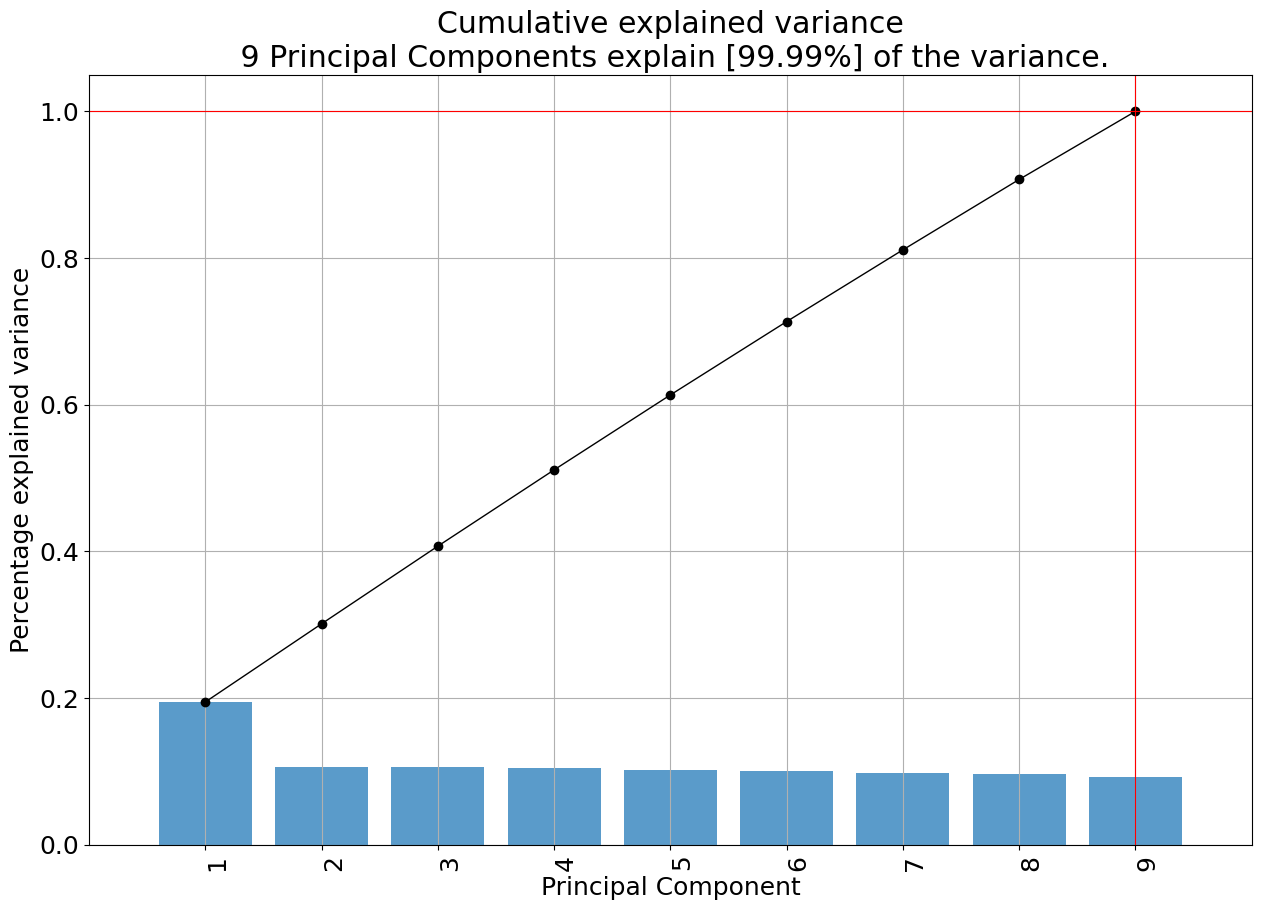

[09-09-2025 13:41:02] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[09-09-2025 13:41:02] [scatterd.scatterd] [INFO] Create scatterplot


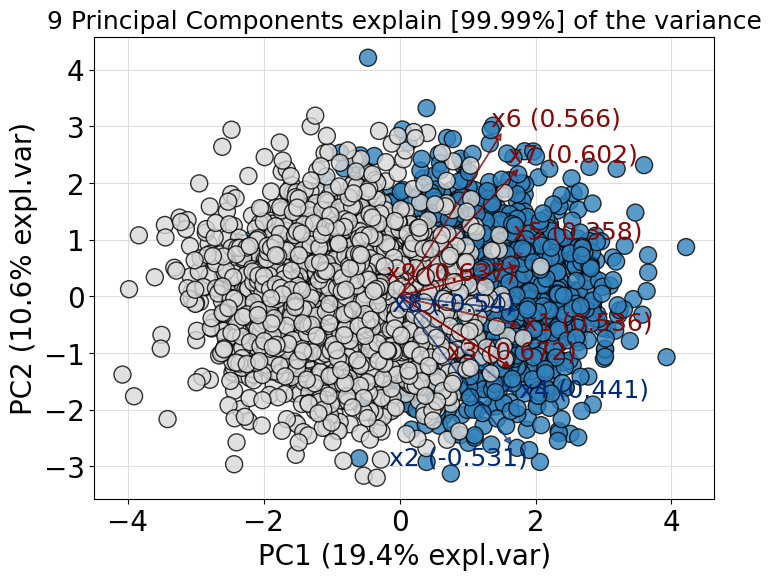

In [7]:
# ==========================
# Datos d=9
# ==========================
datos = crea_datos(n=2000, d=9, C=1, n_ceros=0, random_state=42)

# Scatter matrix de las primeras 5 columnas
scatter_matrix(datos.iloc[:, :5], c=datos["y"], figsize=(10,10), alpha=0.5, diagonal='kde', marker='o')
plt.suptitle("Scatter matrix primeras 5 variables (d=9)")
plt.show()

# PCA con la librería pca
model = pca(n_components=9, normalize=True)
results = model.fit_transform(datos.iloc[:, :-1])

# Scree plot / varianza explicada
model.plot()  # genera automáticamente scree plot y varianza acumulada
plt.show()

# Biplot de los 2 primeros componentes
model.biplot(PC=[0,1], legend=False, figsize=(8,6), labels=datos['y'])
plt.show()

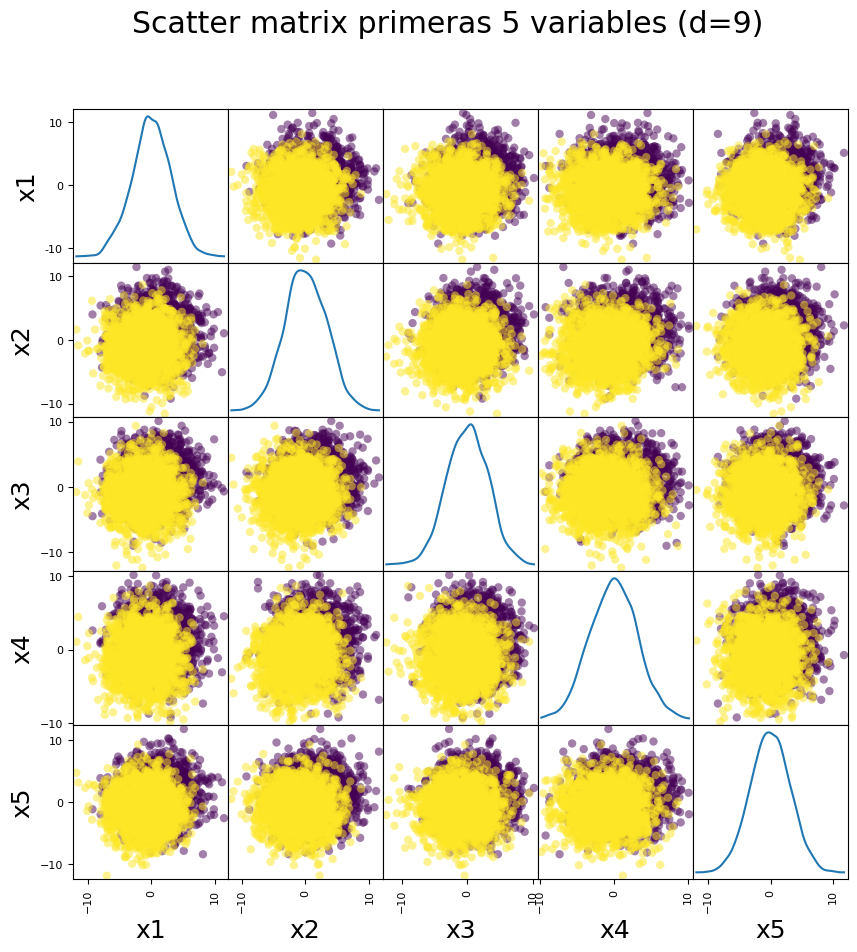

[09-09-2025 13:42:01] [pca.pca] [INFO] Extracting column labels from dataframe.
[09-09-2025 13:42:01] [pca.pca] [INFO] Extracting row labels from dataframe.
[09-09-2025 13:42:01] [pca.pca] [INFO] Normalizing input data per feature (zero mean and unit variance)..
[09-09-2025 13:42:01] [pca.pca] [INFO] The PCA reduction is performed on the 100 columns of the input dataframe.
[09-09-2025 13:42:01] [pca.pca] [INFO] Fit using PCA.
[09-09-2025 13:42:01] [pca.pca] [INFO] Compute loadings and PCs.
[09-09-2025 13:42:01] [pca.pca] [INFO] Compute explained variance.
[09-09-2025 13:42:01] [pca.pca] [INFO] Outlier detection using Hotelling T2 test with alpha=[0.05] and n_components=[9]
[09-09-2025 13:42:04] [pca.pca] [INFO] Multiple test correction applied for Hotelling T2 test: [fdr_bh]
[09-09-2025 13:42:04] [pca.pca] [INFO] Outlier detection using SPE/DmodX with n_std=[3]


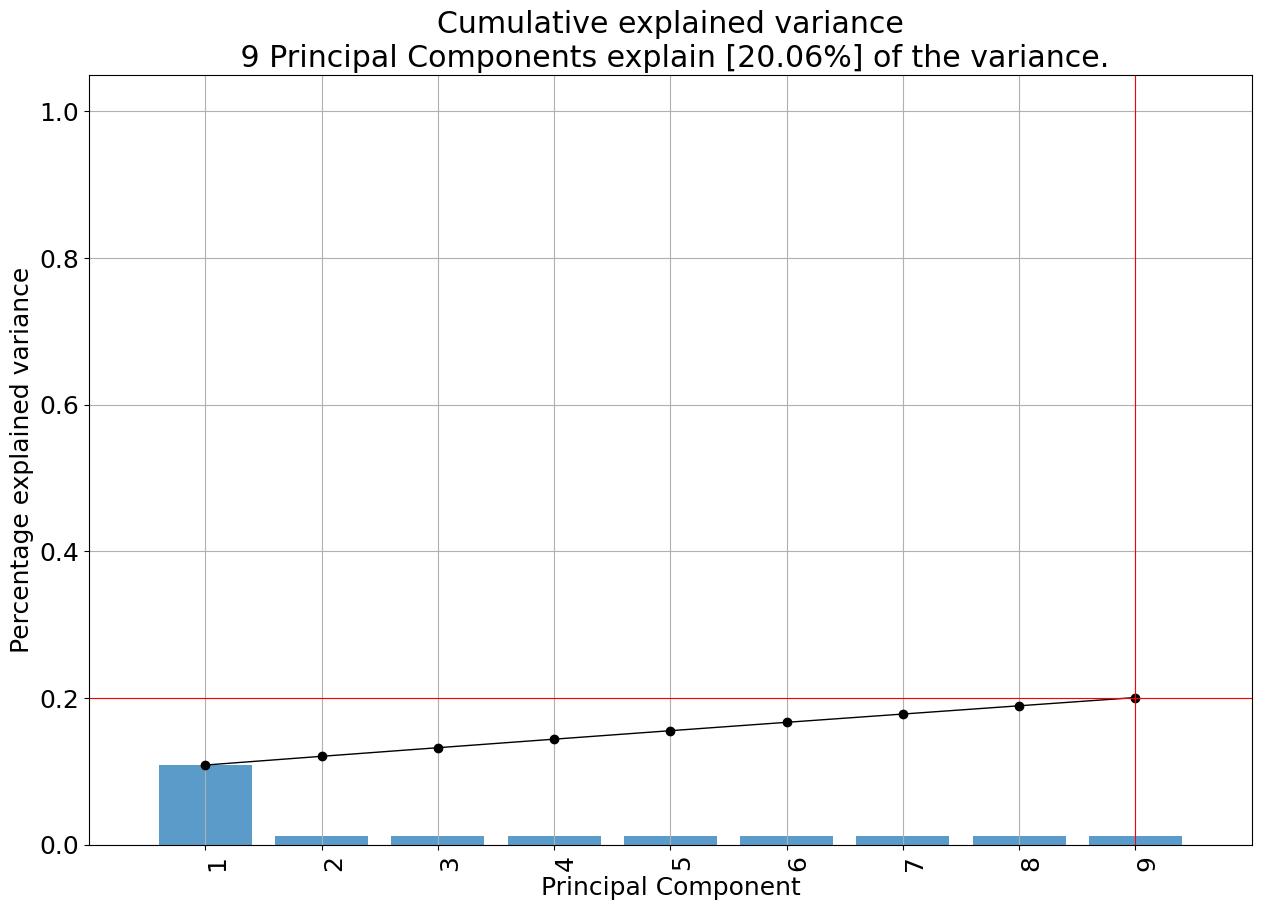

[09-09-2025 13:42:07] [pca.pca] [INFO] Plot PC1 vs PC2 with loadings.
[09-09-2025 13:42:08] [scatterd.scatterd] [INFO] Create scatterplot


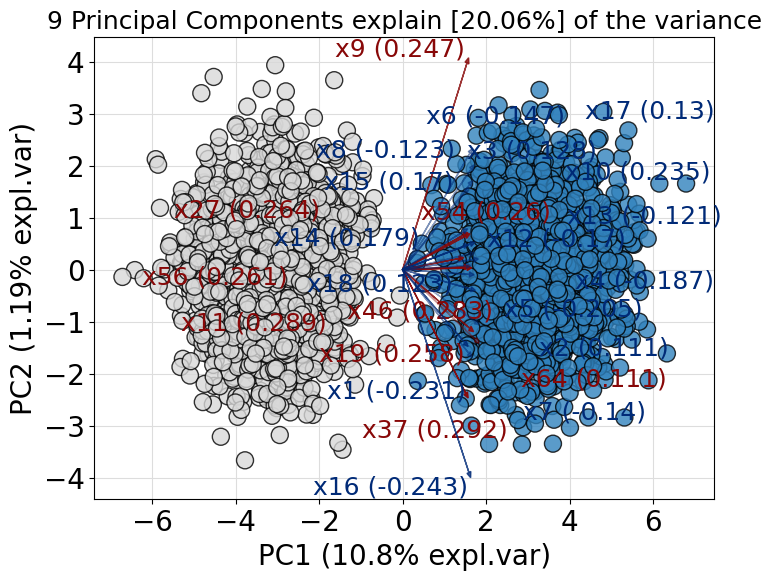

In [12]:
# ==========================
# Datos d=100
# ==========================
datos = crea_datos(n=2000, d=100, C=0.3, n_ceros=0, random_state=42)

# Scatter matrix de las primeras 5 columnas
scatter_matrix(datos.iloc[:, :5], c=datos["y"], figsize=(10,10), alpha=0.5, diagonal='kde', marker='o')
plt.suptitle("Scatter matrix primeras 5 variables (d=9)")
plt.show()

# PCA con la librería pca
model = pca(n_components=9, normalize=True)
results = model.fit_transform(datos.iloc[:, :-1])

# Scree plot / varianza explicada
model.plot()  # genera automáticamente scree plot y varianza acumulada
plt.show()

# Biplot de los 2 primeros componentes
model.biplot(PC=[0,1], legend=False, figsize=(8,6), labels=datos['y'])
plt.show()

# **MDS**

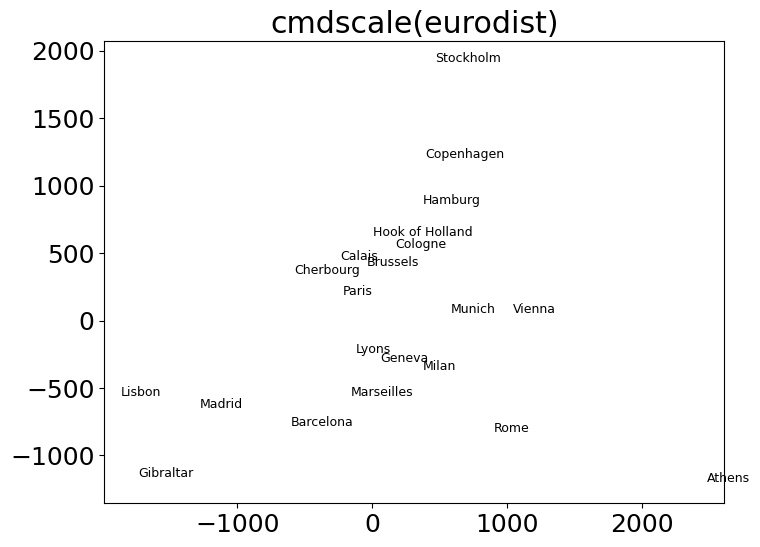

In [8]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.manifold import MDS
from scipy.spatial.distance import squareform

# 1) Cargar dataset eurodist desde R datasets
eurodist = sm.datasets.get_rdataset("eurodist", "datasets").data

# 'x' es el vector de distancias en forma compacta
dist_vector = eurodist['x'].values

# 2) Convertir a matriz cuadrada de distancias
dist_matrix = squareform(dist_vector)

# Los nombres de las ciudades no vienen directamente en la tabla,
# pero están en el dataset original de R (21 ciudades).
cities = [
    "Athens","Barcelona","Brussels","Calais","Cherbourg","Cologne","Copenhagen",
    "Geneva","Gibraltar","Hamburg","Hook of Holland","Lisbon","Lyons","Madrid",
    "Marseilles","Milan","Munich","Paris","Rome","Stockholm","Vienna"
]

# 3) MDS clásico (equivalente a cmdscale)
mds = MDS(n_components=2, dissimilarity="precomputed", random_state=0, metric=True)
loc = mds.fit_transform(dist_matrix)

# 4) Graficar
x, y = loc[:, 0], -loc[:, 1]   # invertir eje Y para parecerse más al de R
plt.figure(figsize=(8, 6))
plt.scatter(y, -x, s=0)  # invisible, solo para setear el espacio
for i, city in enumerate(cities):
    plt.text(y[i], -x[i], city, fontsize=9)

plt.title("cmdscale(eurodist)")
plt.axis("equal")
plt.show()


# **T-SNE**

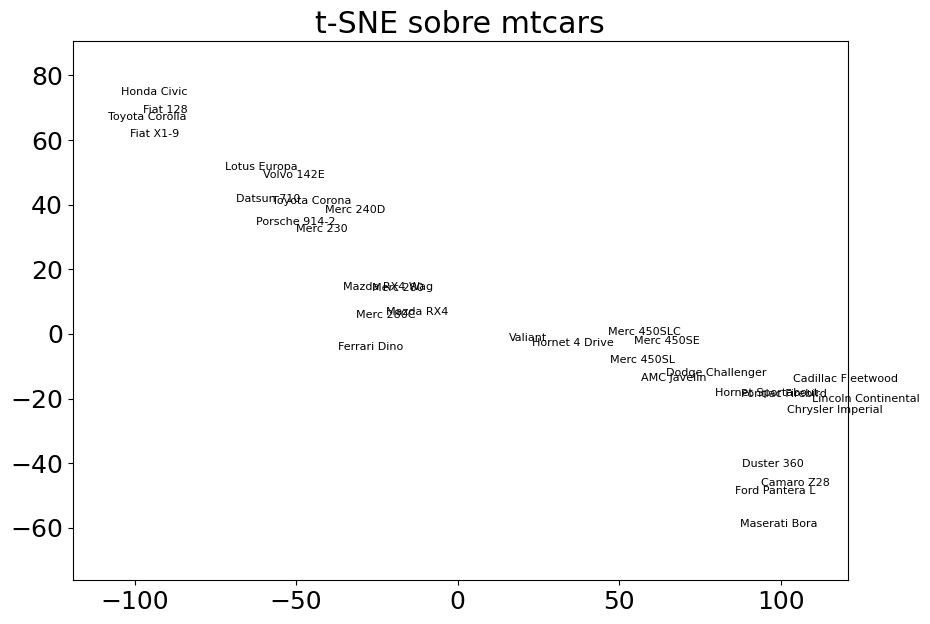

In [9]:
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.manifold import TSNE

# 1) Cargar dataset mtcars
mtcars = sm.datasets.get_rdataset("mtcars", "datasets", cache=True).data

# 2) t-SNE (sobre los datos originales, escala recomendada pero opcional)
tsne = TSNE(n_components=2, random_state=42, perplexity=5)
loc = tsne.fit_transform(mtcars)

# 3) Graficar con nombres de autos
x, y = loc[:, 0], loc[:, 1]
plt.figure(figsize=(10, 7))
plt.scatter(x, y, s=0)  # puntos invisibles, usamos solo etiquetas
for i, name in enumerate(mtcars.index):
    plt.text(x[i], y[i], name, fontsize=8)

plt.title("t-SNE sobre mtcars")
plt.axis("equal")
plt.show()
